In [3]:
from google.colab import userdata
token = userdata.get('GITHUB_TOKEN')
REPO = "smart-waste-multi-agent"

%cd /content
!rm -rf /content/{REPO}
!git clone https://{token}@github.com/Nafila1234/{REPO}.git
%cd /content/{REPO}
!git config user.name "Nafila1234"
!git config user.email "nafiladziri17@gmail.com"
!ls visual_agent

/content
Cloning into 'smart-waste-multi-agent'...
remote: Enumerating objects: 148, done.
remote: Counting objects: 100% (148/148), done.
remote: Compressing objects: 100% (112/112), done.
remote: Total 148 (delta 59), reused 55 (delta 15), pack-reused 0 (from 0)
Receiving objects: 100% (148/148), 1.01 MiB | 10.59 MiB/s, done.
Resolving deltas: 100% (59/59), done.
/content/smart-waste-multi-agent
01_explore_garbage_images.ipynb  README.md	  vision_agent.py
02_cnn_baseline.ipynb		 split.csv
03_vision_agent_test.ipynb	 split_dedup.csv


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
!mkdir -p /content/garbage
!unzip -q "/content/archive (1).zip" -d /content/garbage

Test accuracy: 0.9314 (611/656)
Loading + inference: 108.7 ms/image on cpu
Mean confidence, correct: 0.976 | wrong: 0.783

Threshold | % auto-sorted | accuracy on auto-sorted
  0.50    |     99.7%     |    93.27%
  0.60    |     98.0%     |    93.93%
  0.70    |     95.3%     |    95.36%
  0.80    |     92.1%     |    97.02%
  0.90    |     88.7%     |    97.94%
              precision    recall  f1-score   support

     battery       0.97      0.98      0.98       117
       glass       0.91      0.91      0.91       116
       metal       0.91      0.91      0.91       107
     organic       0.97      0.99      0.98       116
       paper       0.96      0.97      0.96        92
     plastic       0.87      0.83      0.85       108

    accuracy                           0.93       656
   macro avg       0.93      0.93      0.93       656
weighted avg       0.93      0.93      0.93       656



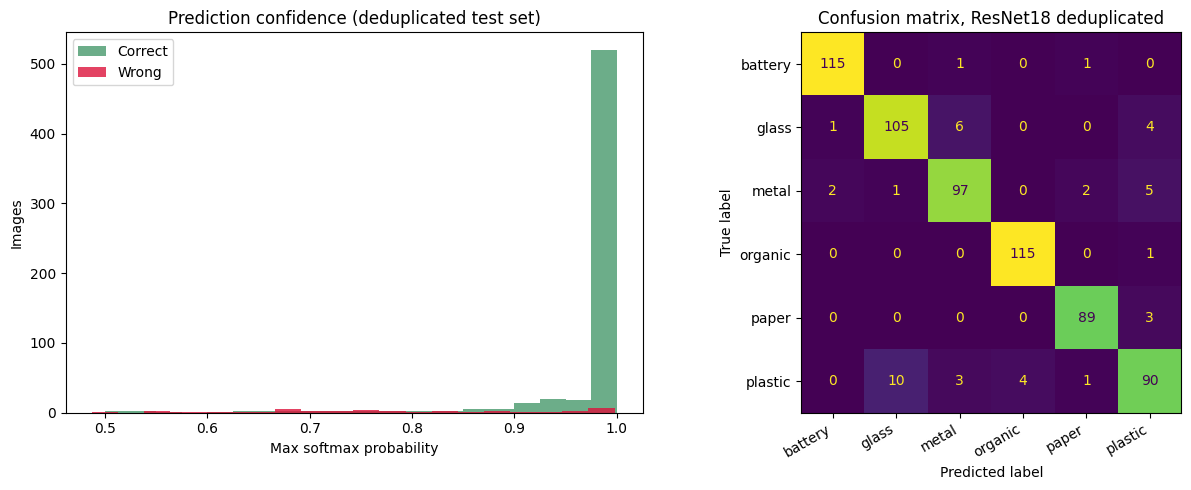

In [6]:
import os, sys, time
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

REPO_DIR = "/content/smart-waste-multi-agent"
DATA_DIR = "/content/garbage"
FIG_DIR = f"{REPO_DIR}/visual_agent/figures"
os.makedirs(FIG_DIR, exist_ok=True)

sys.path.append(f"{REPO_DIR}/visual_agent")
from vision_agent import load_model, CLASSES

device = "cuda" if torch.cuda.is_available() else "cpu"
model = load_model("/content/drive/MyDrive/DM_Project/vision_agent_resnet18_dedup.pth")

tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
split_df = pd.read_csv(f"{REPO_DIR}/visual_agent/split_dedup.csv")
test_df = split_df[split_df["split"] == "test"].reset_index(drop=True)

class TestDS(Dataset):
    def __len__(self): return len(test_df)
    def __getitem__(self, i):
        r = test_df.iloc[i]
        img = Image.open(os.path.join(DATA_DIR, r.file)).convert("RGB")
        return tf(img), class_to_idx[r.label]

test_dl = DataLoader(TestDS(), batch_size=32, num_workers=2)

preds, truth, confs = [], [], []
t0 = time.perf_counter()
with torch.no_grad():
    for x, y in test_dl:
        probs = torch.softmax(model(x.to(device)), dim=1)
        c, p = probs.max(dim=1)
        preds += p.cpu().tolist(); confs += c.cpu().tolist(); truth += y.tolist()
elapsed = time.perf_counter() - t0

preds, truth, confs = np.array(preds), np.array(truth), np.array(confs)
correct = preds == truth
print(f"Test accuracy: {correct.mean():.4f} ({correct.sum()}/{len(truth)})")
print(f"Loading + inference: {elapsed/len(truth)*1000:.1f} ms/image on {device}")
print(f"Mean confidence, correct: {confs[correct].mean():.3f} | wrong: {confs[~correct].mean():.3f}\n")

print("Threshold | % auto-sorted | accuracy on auto-sorted")
for th in [0.50, 0.60, 0.70, 0.80, 0.90]:
    m = confs >= th
    print(f"  {th:.2f}    |    {m.mean()*100:5.1f}%     |    {correct[m].mean()*100:5.2f}%")

print(classification_report(truth, preds, target_names=CLASSES))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(confs[correct], bins=20, alpha=0.7, label="Correct", color="seagreen")
axes[0].hist(confs[~correct], bins=20, alpha=0.8, label="Wrong", color="crimson")
axes[0].set_title("Prediction confidence (deduplicated test set)")
axes[0].set_xlabel("Max softmax probability"); axes[0].set_ylabel("Images"); axes[0].legend()
ConfusionMatrixDisplay.from_predictions(truth, preds, display_labels=CLASSES,
                                        ax=axes[1], colorbar=False)
axes[1].set_title("Confusion matrix, ResNet18 deduplicated")
plt.setp(axes[1].get_xticklabels(), rotation=30, ha="right")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/vision_evaluation_dedup.png", dpi=150)
plt.show()

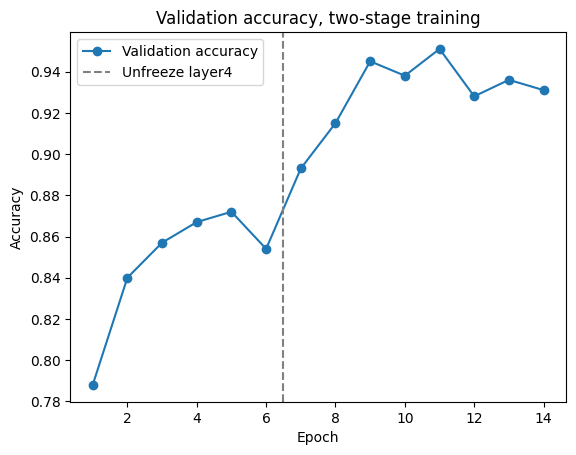

In [7]:
import matplotlib.pyplot as plt
stage1 = [0.788, 0.840, 0.857, 0.867, 0.872, 0.854]
stage2 = [0.893, 0.915, 0.945, 0.938, 0.951, 0.928, 0.936, 0.931]
val = stage1 + stage2
plt.plot(range(1, len(val) + 1), val, marker="o", label="Validation accuracy")
plt.axvline(6.5, color="gray", linestyle="--", label="Unfreeze layer4")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.title("Validation accuracy, two-stage training")
plt.savefig(f"{FIG_DIR}/val_accuracy_dedup.png", dpi=150)
plt.show()

In [8]:
!ls /content/smart-waste-multi-agent/visual_agent/figures

val_accuracy_dedup.png	vision_evaluation_dedup.png
